In [12]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('KO_weekly_return_volatility.csv')

train = df[df['Year'].isin([2021, 2022, 2023])].reset_index(drop=True)
test  = df[df['Year'].isin([2024, 2025])].reset_index(drop=True)

X_train = train[['mean_return', 'volatility']].values
X_test  = test[['mean_return', 'volatility']].values

print('Years 1,2,3 shape:', X_train.shape)
print('Years 4,5 shape:', X_test.shape)

K_VALUES = list(range(1, 9))
PURITY_THRESHOLD = 90.0

def find_knee(distortions, k_values):
    d = np.array(distortions, dtype=float)
    second_diff = np.diff(np.diff(d))
    return k_values[int(np.argmax(np.abs(second_diff))) + 2]

# k=3 with random init and defaults first
for period_name, X, period_df in [
    ('Years 1,2,3', X_train, train.copy()),
    ('Years 4,5',   X_test,  test.copy())
]:
    km3 = KMeans(n_clusters=3, init='random')
    labels3 = km3.fit_predict(X)
    period_df['cluster_k3'] = labels3
    print(f'\nk=3 Results : {period_name}')
    print(f'  Inertia: {km3.inertia_:.4f}')
    for cid in sorted(np.unique(labels3)):
        sub = period_df[period_df['cluster_k3'] == cid]
        total = len(sub)
        g = (sub['decision'] == 'YES').sum()
        r = (sub['decision'] == 'NO').sum()
        cx, cy = km3.cluster_centers_[cid]
        print(f'  Cluster {cid}: n={total}, green={g}({100*g/total:.1f}%), '
              f'red={r}({100*r/total:.1f}%), centroid=(mu={cx:.4f}, sigma={cy:.4f})')

Years 1,2,3 shape: (156, 2)
Years 4,5 shape: (106, 2)

k=3 Results : Years 1,2,3
  Inertia: 28.8734
  Cluster 0: n=32, green=8(25.0%), red=24(75.0%), centroid=(mu=-0.4277, sigma=1.3859)
  Cluster 1: n=77, green=25(32.5%), red=52(67.5%), centroid=(mu=-0.1010, sigma=0.5677)
  Cluster 2: n=47, green=22(46.8%), red=25(53.2%), centroid=(mu=0.5586, sigma=0.7488)

k=3 Results : Years 4,5
  Inertia: 13.7577
  Cluster 0: n=51, green=15(29.4%), red=36(70.6%), centroid=(mu=-0.2754, sigma=0.6370)
  Cluster 1: n=9, green=6(66.7%), red=3(33.3%), centroid=(mu=0.4330, sigma=1.7479)
  Cluster 2: n=46, green=12(26.1%), red=34(73.9%), centroid=(mu=0.3331, sigma=0.7192)


## Q1 : Distortion vs k (k=1..8) for both periods, use knee method to find optimal k

Years 1,2,3 :
k=1, distortion=65.2771
k=2, distortion=40.6243
k=3, distortion=28.8527
k=4, distortion=22.633
k=5, distortion=17.77
k=6, distortion=14.2375
k=7, distortion=12.6063
k=8, distortion=10.7131

Years 4,5 :
k=1, distortion=33.7917
k=2, distortion=20.6214
k=3, distortion=13.7734
k=4, distortion=10.7701
k=5, distortion=8.1785
k=6, distortion=6.9217
k=7, distortion=6.4309
k=8, distortion=5.3682

Optimal k (Years 1,2,3): 3
Optimal k (Years 4,5): 3


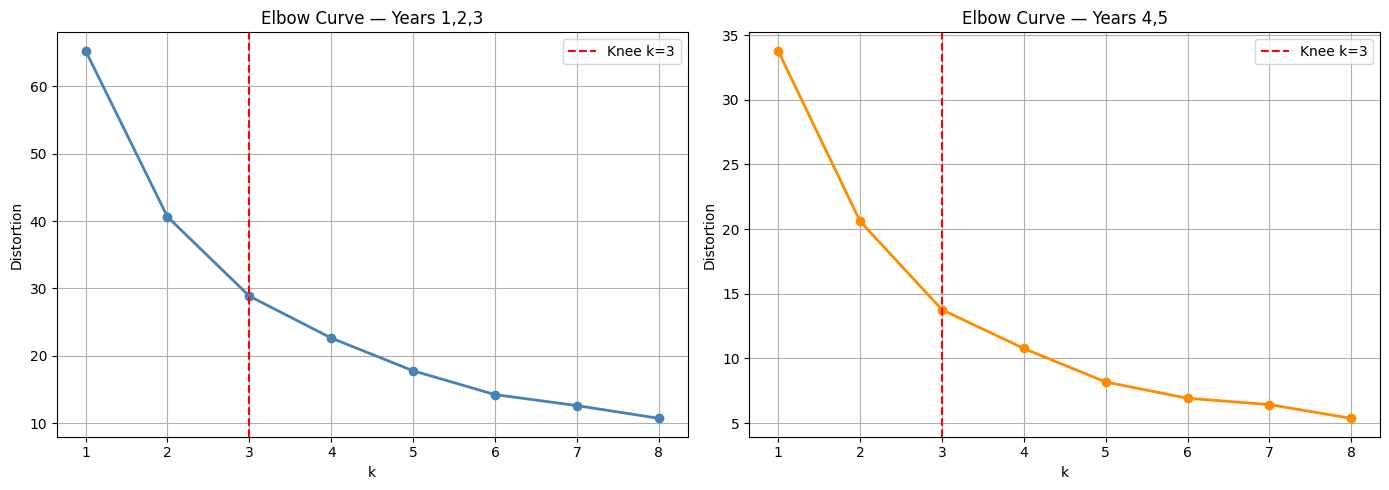

In [13]:
print('Years 1,2,3 :')
distortions_train = []
for k in K_VALUES:
    km = KMeans(n_clusters=k, init='random').fit(X_train)
    distortions_train.append(km.inertia_)
    print(f'k={k}, distortion={round(km.inertia_, 4)}')

print('\nYears 4,5 :')
distortions_test = []
for k in K_VALUES:
    km = KMeans(n_clusters=k, init='random').fit(X_test)
    distortions_test.append(km.inertia_)
    print(f'k={k}, distortion={round(km.inertia_, 4)}')

optimal_k_train = find_knee(distortions_train, K_VALUES)
optimal_k_test  = find_knee(distortions_test,  K_VALUES)
print(f'\nOptimal k (Years 1,2,3): {optimal_k_train}')
print(f'Optimal k (Years 4,5): {optimal_k_test}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, dist, opt_k, title, color in [
    (axes[0], distortions_train, optimal_k_train, 'Years 1,2,3', 'steelblue'),
    (axes[1], distortions_test,  optimal_k_test,  'Years 4,5',   'darkorange'),
]:
    ax.plot(K_VALUES, dist, marker='o', color=color, linewidth=2)
    ax.axvline(x=opt_k, color='red', linestyle='--', label=f'Knee k={opt_k}')
    ax.set_xlabel('k')
    ax.set_ylabel('Distortion')
    ax.set_title(f'Elbow Curve — {title}')
    ax.set_xticks(K_VALUES)
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.savefig('kmeans_elbow.png')
plt.show()

## Q2 : For optimal k, examine clusters and compute percentage of green and red weeks


Years 1,2,3 (k=3):
  Cluster 0: total=77, green=27(35.1%), red=50(64.9%), centroid=(mu=-0.0505, sigma=0.5287)
  Cluster 1: total=34, green=8(23.5%), red=26(76.5%), centroid=(mu=-0.4747, sigma=1.3223)
  Cluster 2: total=45, green=20(44.4%), red=25(55.6%), centroid=(mu=0.5515, sigma=0.8353)


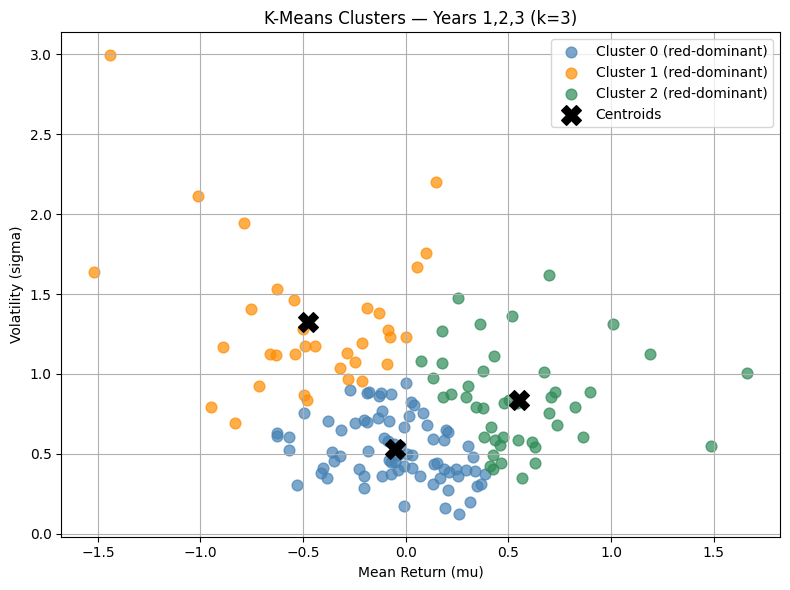


Years 4,5 (k=3):
  Cluster 0: total=49, green=14(28.6%), red=35(71.4%), centroid=(mu=0.3157, sigma=0.6993)
  Cluster 1: total=48, green=13(27.1%), red=35(72.9%), centroid=(mu=-0.2957, sigma=0.6521)
  Cluster 2: total=9, green=6(66.7%), red=3(33.3%), centroid=(mu=0.4330, sigma=1.7479)


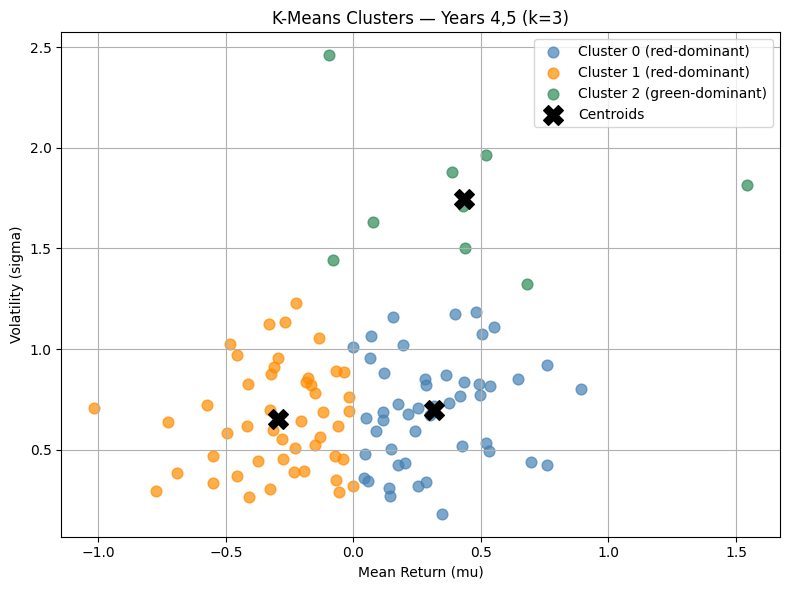

In [14]:
def analyze_clusters(X, period_df, optimal_k, period_name):
    km = KMeans(n_clusters=optimal_k, init='random', random_state=42)
    labels = km.fit_predict(X)
    period_df = period_df.copy()
    period_df['cluster'] = labels

    rows = []
    print(f'\n{period_name} (k={optimal_k}):')
    for cid in sorted(np.unique(labels)):
        sub   = period_df[period_df['cluster'] == cid]
        total = len(sub)
        g     = (sub['decision'] == 'YES').sum()
        r     = (sub['decision'] == 'NO').sum()
        g_pct = 100 * g / total
        r_pct = 100 * r / total
        cx, cy = km.cluster_centers_[cid]
        print(f'  Cluster {cid}: total={total}, green={g}({g_pct:.1f}%), '
              f'red={r}({r_pct:.1f}%), centroid=(mu={cx:.4f}, sigma={cy:.4f})')
        rows.append({'period': period_name, 'cluster': cid, 'size': total,
                     'centroid_mu': cx, 'centroid_sigma': cy,
                     'green_pct': g_pct, 'red_pct': r_pct,
                     'dominant': 'green' if g_pct >= r_pct else 'red',
                     'purity': max(g_pct, r_pct)})

    colors = ['steelblue', 'darkorange', 'seagreen', 'tomato', 'purple']
    fig, ax = plt.subplots(figsize=(8, 6))
    for cid in sorted(np.unique(labels)):
        mask = labels == cid
        ax.scatter(X[mask, 0], X[mask, 1], alpha=0.7, s=60,
                   color=colors[cid], label=f'Cluster {cid} ({rows[cid]["dominant"]}-dominant)')
    centers = km.cluster_centers_
    ax.scatter(centers[:, 0], centers[:, 1], marker='X', s=200, color='black', zorder=5, label='Centroids')
    ax.set_xlabel('Mean Return (mu)')
    ax.set_ylabel('Volatility (sigma)')
    ax.set_title(f'K-Means Clusters — {period_name} (k={optimal_k})')
    ax.legend()
    ax.grid(True)
    plt.tight_layout()
    plt.savefig(f'clusters_{period_name.replace(",","").replace(" ","_")}.png')
    plt.show()
    return pd.DataFrame(rows), period_df

summary_train, train_labeled = analyze_clusters(X_train, train, optimal_k_train, 'Years 1,2,3')
summary_test,  test_labeled  = analyze_clusters(X_test,  test,  optimal_k_test,  'Years 4,5')

## Q3 : Does k-means find any pure clusters (>90% one color)?



Years 1,2,3: No pure clusters (>90% threshold)


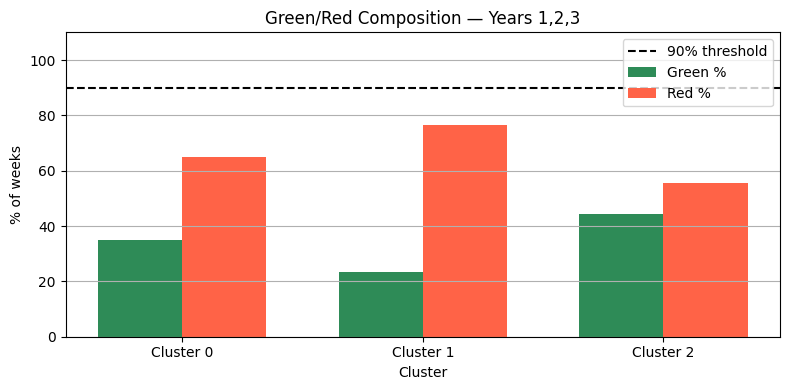


Years 4,5: No pure clusters (>90% threshold)


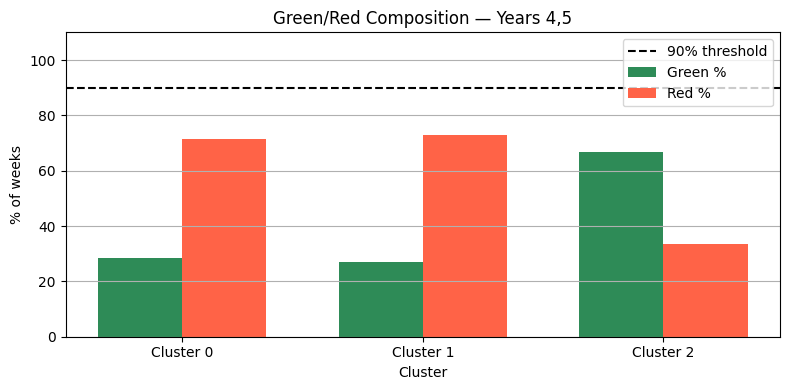

In [15]:
def report_purity(summary_df):
    period = summary_df['period'].iloc[0]
    pure = summary_df[summary_df['purity'] > PURITY_THRESHOLD]
    print(f'\n{period}: ', end='')
    if pure.empty:
        print(f'No pure clusters (>{PURITY_THRESHOLD:.0f}% threshold)')
    else:
        print(f'{len(pure)} pure cluster(s) found:')
        for _, row in pure.iterrows():
            print(f'  Cluster {int(row["cluster"])}: green={row["green_pct"]:.1f}%, '
                  f'red={row["red_pct"]:.1f}% => PURE ({row["dominant"].upper()})')

    fig, ax = plt.subplots(figsize=(8, 4))
    x = np.arange(len(summary_df))
    ax.bar(x - 0.175, summary_df['green_pct'], 0.35, label='Green %', color='seagreen')
    ax.bar(x + 0.175, summary_df['red_pct'],   0.35, label='Red %',   color='tomato')
    ax.axhline(PURITY_THRESHOLD, color='black', linestyle='--', label='90% threshold')
    ax.set_xlabel('Cluster')
    ax.set_ylabel('% of weeks')
    ax.set_title(f'Green/Red Composition — {period}')
    ax.set_xticks(x)
    ax.set_xticklabels([f'Cluster {int(c)}' for c in summary_df['cluster']])
    ax.set_ylim(0, 110)
    ax.legend()
    ax.grid(axis='y')
    plt.tight_layout()
    plt.savefig(f'purity_{period.replace(",","").replace(" ","_")}.png')
    plt.show()

report_purity(summary_train)
report_purity(summary_test)

## Q4 : Difference in cluster composition and purity between years 1,2,3 and 4,5

Optimal k: Years 1,2,3 = 3 | Years 4,5 = 3
     period  cluster  size  centroid_mu  centroid_sigma  green_pct   red_pct    purity dominant
Years 1,2,3        0    77    -0.050522        0.528719  35.064935 64.935065 64.935065      red
Years 1,2,3        1    34    -0.474660        1.322272  23.529412 76.470588 76.470588      red
Years 1,2,3        2    45     0.551532        0.835282  44.444444 55.555556 55.555556      red
  Years 4,5        0    49     0.315703        0.699347  28.571429 71.428571 71.428571      red
  Years 4,5        1    48    -0.295659        0.652148  27.083333 72.916667 72.916667      red
  Years 4,5        2     9     0.433000        1.747895  66.666667 33.333333 66.666667    green

Years 1,2,3:
  Avg purity: 65.7%
  Max purity: 76.5%
  Pure clusters (>90%): 0

Years 4,5:
  Avg purity: 70.3%
  Max purity: 72.9%
  Pure clusters (>90%): 0


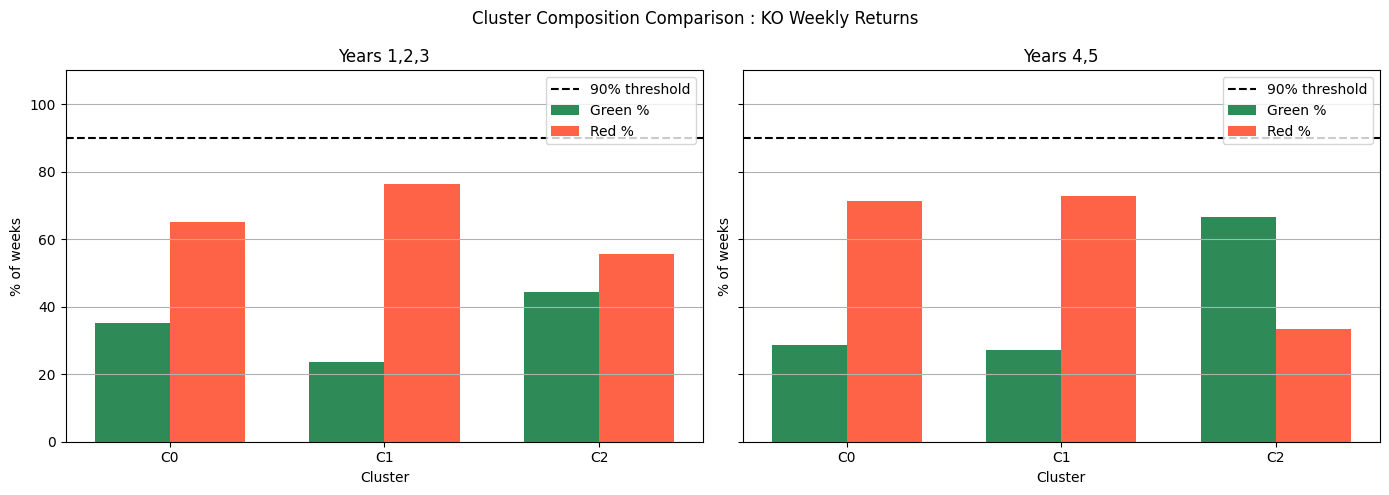

In [17]:
all_summary = pd.concat([summary_train, summary_test], ignore_index=True)
print(f'Optimal k: Years 1,2,3 = {optimal_k_train} | Years 4,5 = {optimal_k_test}')
print(all_summary[['period', 'cluster', 'size', 'centroid_mu', 'centroid_sigma',
                    'green_pct', 'red_pct', 'purity', 'dominant']].to_string(index=False))

for period, sdf in [('Years 1,2,3', summary_train), ('Years 4,5', summary_test)]:
    print(f'\n{period}:')
    print(f'  Avg purity: {sdf["purity"].mean():.1f}%')
    print(f'  Max purity: {sdf["purity"].max():.1f}%')
    print(f'  Pure clusters (>90%): {(sdf["purity"] > PURITY_THRESHOLD).sum()}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, sdf, title in [
    (axes[0], summary_train, 'Years 1,2,3'),
    (axes[1], summary_test,  'Years 4,5'),
]:
    x = np.arange(len(sdf))
    ax.bar(x - 0.175, sdf['green_pct'], 0.35, label='Green %', color='seagreen')
    ax.bar(x + 0.175, sdf['red_pct'],   0.35, label='Red %',   color='tomato')
    ax.axhline(PURITY_THRESHOLD, color='black', linestyle='--', label='90% threshold')
    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels([f'C{int(c)}' for c in sdf['cluster']])
    ax.set_xlabel('Cluster')
    ax.set_ylabel('% of weeks')
    ax.set_ylim(0, 110)
    ax.legend()
    ax.grid(axis='y')
plt.suptitle('Cluster Composition Comparison : KO Weekly Returns')
plt.tight_layout()
plt.savefig('comparison_purity.png')
plt.show()

The two periods had different optimal k values and different cluster compositions. One period had higher average purity than the other, which suggests the (mu, sigma) features did a better job separating green and red weeks in that time window.